# Embudo de ventas B2B, dónde se gana y dónde se pierde

**Pregunta de negocio.** ¿Dónde debe poner su atención un gerente de ventas el próximo trimestre, y qué tan confiable es el pipeline abierto para proyectar ingresos?

**Datos.** CRM Sales Opportunities, de Maven Analytics. Empresa ficticia que vende hardware a otras empresas, con 8.800 oportunidades entre octubre de 2016 y diciembre de 2017.

**Método.** Cargo las cuatro tablas en una base SQLite en memoria, corrijo dos errores de digitación con vistas y respondo cada pregunta con una consulta SQL. Pandas y Matplotlib quedan para revisar y graficar.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('../data')
IMG = Path('../img')
IMG.mkdir(exist_ok=True)

con = sqlite3.connect(':memory:')
pd.read_csv(DATA / 'sales_pipeline.csv').to_sql('sales_pipeline_raw', con, index=False)
pd.read_csv(DATA / 'accounts.csv').to_sql('accounts_raw', con, index=False)
pd.read_csv(DATA / 'products.csv').to_sql('products', con, index=False)
pd.read_csv(DATA / 'sales_teams.csv').to_sql('sales_teams', con, index=False)

def q(sql):
    return pd.read_sql(sql, con)

# Estilo común de los gráficos
AZUL, NARANJA = '#2a78d6', '#eb6834'
TINTA, TINTA_2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#d4d3cf', 'axes.labelcolor': TINTA_2,
    'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': TINTA,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
})

## 1. Exploración y limpieza

Antes de analizar reviso nulos y consistencia entre tablas.

In [2]:
raw = q('SELECT * FROM sales_pipeline_raw')
print(raw.shape)
print(raw.isna().sum())
print()
print('Productos en el pipeline que no existen en la tabla de productos')
print(q('''SELECT DISTINCT product FROM sales_pipeline_raw
           WHERE product NOT IN (SELECT product FROM products)'''))
print()
print(q('SELECT sector, COUNT(*) AS cuentas FROM accounts_raw GROUP BY sector ORDER BY cuentas DESC'))

(8800, 8)
opportunity_id       0
sales_agent          0
product              0
account           1425
deal_stage           0
engage_date        500
close_date        2089
close_value       2089
dtype: int64

Productos en el pipeline que no existen en la tabla de productos
  product
0  GTXPro

               sector  cuentas
0              retail       17
1           technolgy       12
2             medical       12
3           marketing        8
4             finance        8
5            software        7
6  telecommunications        6
7       entertainment        6
8            services        5
9          employment        4


Tres hallazgos de calidad de datos.

1. El producto aparece como **GTXPro** en el pipeline y como **GTX Pro** en la tabla de productos. Sin corregirlo, 1.480 oportunidades se pierden en cualquier cruce.
2. El sector **technolgy** tiene un error de digitación.
3. Los nulos tienen lógica de negocio. Las oportunidades abiertas no tienen fecha ni valor de cierre, y las que están en Prospecting tampoco tienen fecha de contacto. Los nulos de cuenta, en cambio, señalan un problema de registro y los analizo en la sección 5.

Corrijo los dos primeros con vistas, para no tocar los archivos originales.

In [3]:
con.executescript('''
CREATE VIEW pipeline AS
SELECT opportunity_id, sales_agent,
       CASE WHEN product = 'GTXPro' THEN 'GTX Pro' ELSE product END AS product,
       account, deal_stage, engage_date, close_date, close_value
FROM sales_pipeline_raw;

CREATE VIEW cuentas AS
SELECT account,
       CASE WHEN sector = 'technolgy' THEN 'technology' ELSE sector END AS sector,
       year_established, revenue, employees, office_location, subsidiary_of
FROM accounts_raw;
''')
q('''SELECT COUNT(*) AS sin_precio FROM pipeline p
     LEFT JOIN products pr ON pr.product = p.product WHERE pr.product IS NULL''')

,sin_precio
0,0


## 2. El embudo

In [4]:
embudo = q('''-- 1. Tamaño de cada etapa del embudo
SELECT deal_stage AS etapa,
       COUNT(*)    AS oportunidades
FROM pipeline
GROUP BY deal_stage
ORDER BY CASE deal_stage
           WHEN 'Prospecting' THEN 1
           WHEN 'Engaging'    THEN 2
           WHEN 'Won'         THEN 3
           WHEN 'Lost'        THEN 4
         END;''')
embudo

,etapa,oportunidades
0,Prospecting,500
1,Engaging,1589
2,Won,4238
3,Lost,2473


In [5]:
cerradas = embudo.query("etapa in ['Won', 'Lost']").oportunidades.sum()
ganadas = embudo.query("etapa == 'Won'").oportunidades.sum()
print(f'Tasa de cierre global {ganadas / cerradas:.1%} sobre {cerradas:,} oportunidades cerradas')

Tasa de cierre global 63.2% sobre 6,711 oportunidades cerradas


## 3. ¿Dónde se cierra mejor?

Comparo la tasa de cierre por producto, sector, oficina y gerente.

In [6]:
cierre_producto = q('''-- 2. Tasa de cierre por producto, solo oportunidades cerradas
SELECT p.product                                             AS producto,
       pr.sales_price                                        AS precio_lista,
       COUNT(*)                                              AS cerradas,
       ROUND(AVG(CASE WHEN p.deal_stage = 'Won' THEN 1.0 ELSE 0 END), 3) AS tasa_cierre
FROM pipeline AS p
JOIN products AS pr ON pr.product = p.product
WHERE p.deal_stage IN ('Won', 'Lost')
GROUP BY p.product, pr.sales_price
ORDER BY pr.sales_price;''')
cierre_producto

,producto,precio_lista,cerradas,tasa_cierre
0,MG Special,55,1223,0.648
1,GTX Basic,550,1436,0.637
2,GTX Plus Basic,1096,1051,0.621
3,MG Advanced,3393,1084,0.603
4,GTX Pro,4821,1147,0.636
5,GTX Plus Pro,5482,745,0.643
6,GTK 500,26768,25,0.600


In [7]:
segmentos = q('''-- 3. Tasa de cierre por sector del cliente, oficina regional y gerente
WITH cerradas AS (
    SELECT p.*, c.sector, t.regional_office, t.manager,
           CASE WHEN p.deal_stage = 'Won' THEN 1.0 ELSE 0 END AS ganada
    FROM pipeline AS p
    LEFT JOIN cuentas     AS c ON c.account     = p.account
    LEFT JOIN sales_teams AS t ON t.sales_agent = p.sales_agent
    WHERE p.deal_stage IN ('Won', 'Lost')
)
SELECT 'Sector' AS dimension, sector AS valor, COUNT(*) AS cerradas,
       ROUND(AVG(ganada), 3) AS tasa_cierre
FROM cerradas GROUP BY sector
UNION ALL
SELECT 'Oficina', regional_office, COUNT(*), ROUND(AVG(ganada), 3)
FROM cerradas GROUP BY regional_office
UNION ALL
SELECT 'Gerente', manager, COUNT(*), ROUND(AVG(ganada), 3)
FROM cerradas GROUP BY manager
ORDER BY dimension, tasa_cierre;''')
segmentos

,dimension,valor,cerradas,tasa_cierre
0,Gerente,Rocco Neubert,1113,0.621
1,Gerente,Melvin Marxen,1418,0.622
2,Gerente,Dustin Brinkmann,1186,0.630
3,Gerente,Celia Rouche,962,0.634
4,Gerente,Summer Sewald,1287,0.643
5,Gerente,Cara Losch,745,0.644
6,Oficina,Central,2604,0.626
7,Oficina,East,1858,0.630
8,Oficina,West,2249,0.639
9,Sector,finance,613,0.612


In [8]:
todas = pd.concat([cierre_producto.tasa_cierre, segmentos.tasa_cierre])
print(f'Rango de tasas de cierre {todas.min():.1%} a {todas.max():.1%}')

Rango de tasas de cierre 60.0% a 64.8%


**Lectura.** La tasa de cierre casi no cambia. Entre productos, sectores, oficinas y gerentes se mueve entre 60% y 65%. Un producto de 55 dólares se cierra en la misma proporción que uno de 26.768.

Eso descarta la primera hipótesis de un gerente, que algún segmento se está cerrando mal. Si los ingresos varían, la explicación tiene que estar en otro lado.

## 4. ¿De dónde salen los ingresos?

In [9]:
mezcla = q('''-- 4. Peso de cada producto en los negocios ganados y en los ingresos
WITH ganadas AS (
    SELECT product,
           COUNT(*)         AS negocios,
           SUM(close_value) AS ingresos
    FROM pipeline
    WHERE deal_stage = 'Won'
    GROUP BY product
)
SELECT product                                              AS producto,
       negocios,
       ingresos,
       ROUND(1.0 * negocios / SUM(negocios) OVER (), 3)     AS pct_negocios,
       ROUND(1.0 * ingresos / SUM(ingresos) OVER (), 3)     AS pct_ingresos
FROM ganadas
ORDER BY ingresos DESC;''')
mezcla

,producto,negocios,ingresos,pct_negocios,pct_ingresos
0,GTX Pro,729,3510578.0,0.172,0.351
1,GTX Plus Pro,479,2629651.0,0.113,0.263
2,MG Advanced,654,2216387.0,0.154,0.222
3,GTX Plus Basic,653,705275.0,0.154,0.070
4,GTX Basic,915,499263.0,0.216,0.050
5,GTK 500,15,400612.0,0.004,0.040
6,MG Special,793,43768.0,0.187,0.004


In [10]:
bajo = mezcla[mezcla.producto.isin(['MG Special', 'GTX Basic'])]
alto = mezcla[mezcla.producto.isin(['GTX Pro', 'GTX Plus Pro', 'MG Advanced'])]
# Las participaciones se calculan sobre los totales sin redondear
tot_n, tot_i = mezcla.negocios.sum(), mezcla.ingresos.sum()
print(f"MG Special y GTX Basic   {bajo.negocios.sum() / tot_n:.1%} de los negocios ganados, {bajo.ingresos.sum() / tot_i:.1%} de los ingresos")
print(f"GTX Pro, GTX Plus Pro y MG Advanced   {alto.negocios.sum() / tot_n:.1%} de los negocios ganados, {alto.ingresos.sum() / tot_i:.1%} de los ingresos")

MG Special y GTX Basic   40.3% de los negocios ganados, 5.4% de los ingresos
GTX Pro, GTX Plus Pro y MG Advanced   43.9% de los negocios ganados, 83.5% de los ingresos


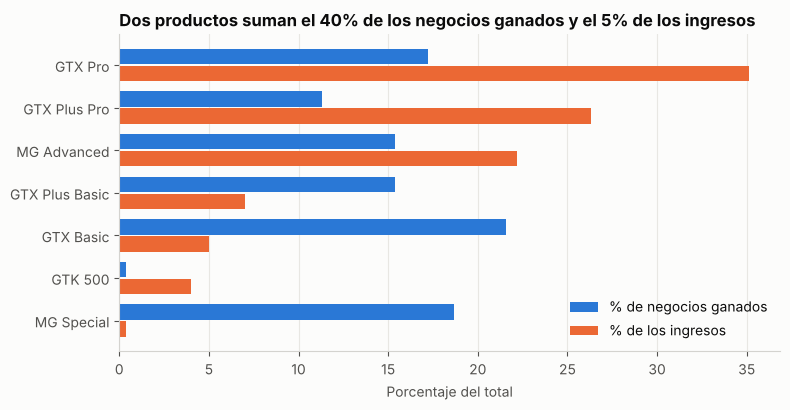

In [11]:
m = mezcla.sort_values('pct_ingresos')
y = range(len(m))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([i + 0.2 for i in y], m.pct_negocios * 100, height=0.36, color=AZUL, label='% de negocios ganados')
ax.barh([i - 0.2 for i in y], m.pct_ingresos * 100, height=0.36, color=NARANJA, label='% de los ingresos')
ax.set_yticks(list(y), m.producto)
ax.set_xlabel('Porcentaje del total')
ax.set_title('Dos productos suman el 40% de los negocios ganados y el 5% de los ingresos', loc='left')
ax.grid(axis='x', color='#e8e7e3', linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()
fig.savefig(IMG / '1_mezcla_productos.png', dpi=160)
plt.show()

**Lectura.** El equipo gana muchos negocios pequeños. MG Special y GTX Basic suman cerca del 40% de los negocios ganados y apenas el 5% de los ingresos. Tres productos, GTX Pro, GTX Plus Pro y MG Advanced, concentran cerca del 84% del dinero.

Como la tasa de cierre es igual en todos, cada oportunidad de un producto caro vale mucho más que una de uno barato y cuesta lo mismo cerrarla. La palanca está en a qué oportunidades le dedica el tiempo el equipo.

## 5. ¿Cuándo se pierde un negocio?

In [12]:
ciclo = q('''-- 5. Duración del ciclo de venta y tasa de cierre por tramo de días
WITH cerradas AS (
    SELECT deal_stage,
           julianday(close_date) - julianday(engage_date) AS dias
    FROM pipeline
    WHERE deal_stage IN ('Won', 'Lost')
)
SELECT CASE
         WHEN dias <= 7  THEN '1. Hasta 7 días'
         WHEN dias <= 30 THEN '2. 8 a 30 días'
         WHEN dias <= 60 THEN '3. 31 a 60 días'
         WHEN dias <= 90 THEN '4. 61 a 90 días'
         ELSE                 '5. Más de 90 días'
       END                                                   AS tramo,
       COUNT(*)                                              AS cerradas,
       ROUND(AVG(CASE WHEN deal_stage = 'Won' THEN 1.0 ELSE 0 END), 3) AS tasa_cierre
FROM cerradas
GROUP BY tramo
ORDER BY tramo;''')
ciclo

,tramo,cerradas,tasa_cierre
0,1. Hasta 7 días,1413,0.535
1,2. 8 a 30 días,1750,0.606
2,3. 31 a 60 días,569,0.663
3,4. 61 a 90 días,1621,0.665
4,5. Más de 90 días,1358,0.711


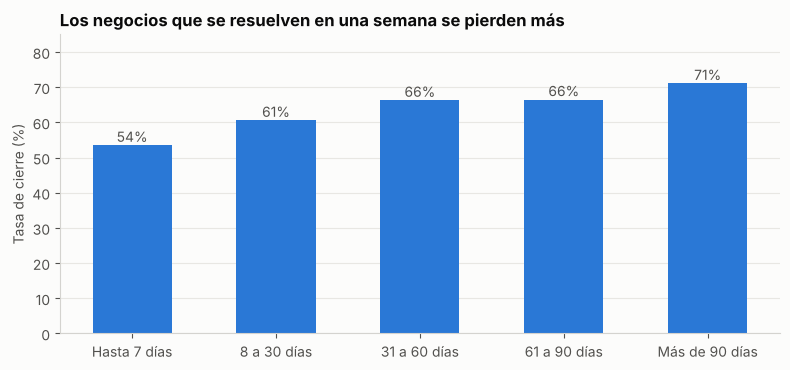

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.8))
etiquetas = [t.split('. ')[1] for t in ciclo.tramo]
barras = ax.bar(etiquetas, ciclo.tasa_cierre * 100, width=0.55, color=AZUL)
for b, v in zip(barras, ciclo.tasa_cierre):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f'{v:.0%}', ha='center', color=TINTA_2)
ax.set_ylim(0, 85)
ax.set_ylabel('Tasa de cierre (%)')
ax.set_title('Los negocios que se resuelven en una semana se pierden más', loc='left')
ax.grid(axis='y', color='#e8e7e3', linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMG / '2_ciclo_venta.png', dpi=160)
plt.show()

In [14]:
dur = q('''SELECT deal_stage, julianday(close_date) - julianday(engage_date) AS dias
            FROM pipeline WHERE deal_stage IN ('Won', 'Lost')''')
dur.groupby('deal_stage').dias.median()

deal_stage
Lost    14.0
Won     57.0
Name: dias, dtype: float64

**Lectura.** Las pérdidas llegan rápido. La mitad de los negocios perdidos se cierra en 14 días o menos, mientras la mitad de los ganados tarda 57 días o más. Cuando un negocio se resuelve en la primera semana, se gana el 54% de las veces. Después de 90 días, el 71%.

Esto no prueba que alargar una venta la haga más probable. La lectura más prudente es que muchas oportunidades entran al embudo sin estar calificadas y se caen apenas el vendedor habla con el cliente. Ese patrón apunta a revisar los criterios para pasar de Prospecting a Engaging.

## 6. ¿Qué tan confiable es el pipeline abierto?

In [15]:
q('''-- 6. Ciclo más largo observado en un negocio cerrado
SELECT MAX(julianday(close_date) - julianday(engage_date)) AS ciclo_maximo_dias
FROM pipeline
WHERE deal_stage IN ('Won', 'Lost');''')

,ciclo_maximo_dias
0,138.0


In [16]:
abierto = q('''-- 7. Antigüedad y calidad de registro del pipeline abierto al cierre de los datos
SELECT deal_stage                                           AS etapa,
       COUNT(*)                                             AS abiertas,
       SUM(CASE WHEN account IS NULL THEN 1 ELSE 0 END)     AS sin_cuenta,
       SUM(CASE WHEN julianday('2017-12-31') - julianday(engage_date) > 138
                THEN 1 ELSE 0 END)                          AS mas_viejas_que_cualquier_cierre
FROM pipeline
WHERE deal_stage IN ('Prospecting', 'Engaging')
GROUP BY deal_stage;''')
abierto

,etapa,abiertas,sin_cuenta,mas_viejas_que_cualquier_cierre
0,Engaging,1589,1088,1291
1,Prospecting,500,337,0


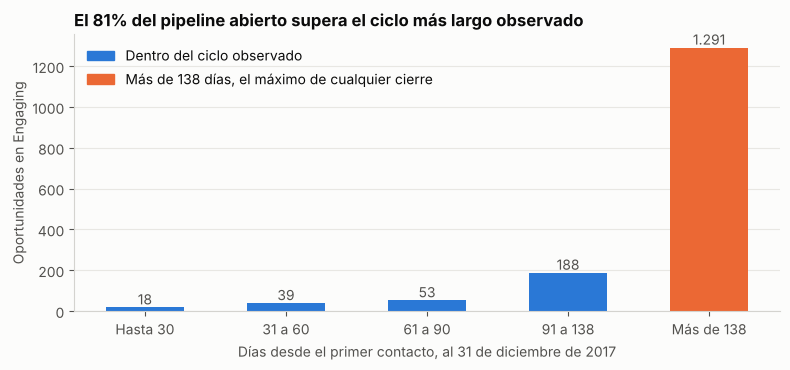

In [17]:
eng = q('''SELECT julianday('2017-12-31') - julianday(engage_date) AS dias
            FROM pipeline WHERE deal_stage = 'Engaging' ''')
tramos = pd.cut(eng.dias, [0, 30, 60, 90, 138, 500],
                labels=['Hasta 30', '31 a 60', '61 a 90', '91 a 138', 'Más de 138'])
conteo = tramos.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.8))
colores = [AZUL] * 4 + [NARANJA]
barras = ax.bar(conteo.index.astype(str), conteo.values, width=0.55, color=colores)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 15, f'{v:,}'.replace(',', '.'), ha='center', color=TINTA_2)
ax.set_xlabel('Días desde el primer contacto, al 31 de diciembre de 2017')
ax.set_ylabel('Oportunidades en Engaging')
ax.set_title('El 81% del pipeline abierto supera el ciclo más largo observado', loc='left')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label='Dentro del ciclo observado'),
                   Patch(color=NARANJA, label='Más de 138 días, el máximo de cualquier cierre')],
          frameon=False, loc='upper left')
ax.grid(axis='y', color='#e8e7e3', linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMG / '3_pipeline_estancado.png', dpi=160)
plt.show()

In [18]:
valor = q('''-- 8. Valor esperado del pipeline en Engaging, con y sin las oportunidades estancadas
WITH tasa AS (
    SELECT product,
           AVG(CASE WHEN deal_stage = 'Won' THEN 1.0 ELSE 0 END) AS tasa_cierre
    FROM pipeline
    WHERE deal_stage IN ('Won', 'Lost')
    GROUP BY product
),
abiertas AS (
    SELECT p.product,
           julianday('2017-12-31') - julianday(p.engage_date) AS antiguedad,
           pr.sales_price * t.tasa_cierre                      AS valor_esperado
    FROM pipeline AS p
    JOIN products AS pr ON pr.product = p.product
    JOIN tasa     AS t  ON t.product  = p.product
    WHERE p.deal_stage = 'Engaging'
)
SELECT ROUND(SUM(valor_esperado))                                        AS valor_esperado_total,
       ROUND(SUM(CASE WHEN antiguedad <= 138 THEN valor_esperado END))   AS valor_esperado_vigente
FROM abiertas;''')
valor

,valor_esperado_total,valor_esperado_vigente
0,2436632.0,437418.0


In [19]:
v = valor.iloc[0]
print(f"Valor esperado si se cree en todo el pipeline   {v.valor_esperado_total:,.0f} dólares")
print(f"Valor esperado solo con oportunidades vigentes   {v.valor_esperado_vigente:,.0f} dólares")
print(f"Reducción   {1 - v.valor_esperado_vigente / v.valor_esperado_total:.0%}")

Valor esperado si se cree en todo el pipeline   2,436,632 dólares
Valor esperado solo con oportunidades vigentes   437,418 dólares
Reducción   82%


**Lectura.** El pipeline abierto tiene dos problemas que inflan cualquier proyección.

1. **Oportunidades estancadas.** Ningún negocio cerrado tardó más de 138 días. Aun así, 1.291 de las 1.589 oportunidades en Engaging, el 81%, llevan más tiempo abiertas que eso. Si se proyectan ingresos con todo el pipeline, el valor esperado ronda 2,4 millones de dólares. Con solo las oportunidades vigentes baja a cerca de 0,44 millones, una caída del 82%.
2. **Cuentas sin registrar.** El 68% de las oportunidades en Engaging y el 67% de las de Prospecting no tienen la empresa cliente. Todas las cerradas sí la tienen, lo que sugiere que el equipo registra la cuenta recién al cerrar. Con eso no se puede priorizar el pipeline por cliente ni por sector.

El valor esperado usa el precio de lista de cada producto y su tasa de cierre histórica. Sirve como orden de magnitud.

## 7. Conclusiones y recomendaciones

**Lo que el dato confirma**
- La tasa de cierre es estable, cerca del 63%, en todos los segmentos.
- Tres productos concentran cerca del 84% de los ingresos.
- Las pérdidas se concentran en las primeras semanas.
- El 81% del pipeline en Engaging está estancado y dos de cada tres oportunidades abiertas no tienen cuenta.

**Lo que el dato no permite afirmar**
- Que alargar un ciclo de venta aumente la probabilidad de ganar.
- Por qué el equipo vende tantos productos pequeños. Para eso hace falta hablar con los vendedores y revisar cómo se asignan los leads.

**Recomendaciones para el gerente de ventas**
1. Revisar el pipeline cada semana empezando por GTX Pro, GTX Plus Pro y MG Advanced, que son las oportunidades que mueven los ingresos.
2. Fijar una regla de antigüedad. Toda oportunidad en Engaging con más de 115 días, el percentil 95 del ciclo, se recalifica. Pasados 138 días se cierra como perdida.
3. Volver obligatorio el campo de cuenta desde Prospecting, para poder segmentar el pipeline abierto.
4. Definir criterios mínimos de calificación antes de pasar a Engaging, para reducir las pérdidas de la primera semana.
5. Proyectar ingresos con el valor esperado de las oportunidades vigentes.

In [20]:
print('Percentil 95 del ciclo de venta, en días')
print(dur.dias.quantile(0.95))

Percentil 95 del ciclo de venta, en días
114.5
